In [6]:
import pybamm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("..")
from DC1 import DC1
from DFN import DFN

In [7]:
paramsDFN = pybamm.ParameterValues({
    # Geometry
    "L_sep": 12e-6,
    "L_anode": 85.2e-6,
    "L_cathode": 75.6e-6,

    # Butler-Folmer anode, negative (C)
    "Fk_anode": 6.48e-7,
    "C_max_anode": 33133,
    "U_anode": lambda x: (
        1.9793 * pybamm.exp(-39.3631 * x) + 0.2482
        - 0.0909 * pybamm.tanh(29.8538 * (x - 0.1234))
        - 0.04478 * pybamm.tanh(14.9159 * (x - 0.2769))
        - 0.0205 * pybamm.tanh(30.4444 * (x - 0.6103))
    ),

    # Butler-Folmer cathode, positive (NMC)
    "Fk_cathode": 3.42e-6,
    "C_max_cathode": 63104,
    "U_cathode": lambda x: (
        -0.8090 * x + 4.4875
        - 0.0428 * pybamm.tanh(18.5138 * (x - 0.5542))
        - 17.7326 * pybamm.tanh(15.7890 * (x - 0.3117))
        + 17.5842 * pybamm.tanh(15.9308 * (x - 0.3120))
    ),

    # Electrolyte
    "D_e": lambda c: 8.794e-11 * (c/1000) ** 2 - 3.972e-10 * (c/1000) + 4.862e-10,
    "kappa_e": lambda c: 0.1297 * (c/1000) ** 3 - 2.51 * (c/1000) ** 1.5 + 3.329 * (c/1000),
    "t_plus": 0.2594,
    "eps_sep": 0.47,
    "tau_sep": 0.47 / 0.47**1.5,
    "tau_anode": 0.25 / 0.25**1.5,
    "tau_cathode": 0.335 / 0.335**1.5,

    # Solid anode
    "eps_s_anode": 0.75,
    "kappa_s_anode": 215,
    "R_p_anode": 5.86e-6,
    "D_s_anode": 3.3e-14,

    # Solid cathode
    "eps_s_cathode": 0.665,
    "kappa_s_cathode": 0.18,
    "R_p_cathode": 5.22e-6,
    "D_s_cathode": 4e-15,

    # General
    "T": 298.15,

    # Initial
    "C_e_0": 1000,
    "C_s_0_anode": 0.9014 * 33133,
    "C_s_0_cathode": 0.27 * 63104,
    
    # Cutoff
    "u_min" : 2.5,
    "u_max" : 4.4,
})

In [8]:
paramsDC1 = pybamm.ParameterValues({
    # Geometry
    "L_sep": 12e-6,
    "L_anode": 85.2e-6,
    "L_cathode": 75.6e-6,

    # Butler-Folmer anode, negative (C)
    "Fk_anode": 6.48e-7,
    "C_max_anode": 33133,
    "U_anode": lambda x: (
        1.9793 * pybamm.exp(-39.3631 * x) + 0.2482
        - 0.0909 * pybamm.tanh(29.8538 * (x - 0.1234))
        - 0.04478 * pybamm.tanh(14.9159 * (x - 0.2769))
        - 0.0205 * pybamm.tanh(30.4444 * (x - 0.6103))
    ),

    # Butler-Folmer cathode, positive (NMC)
    "Fk_cathode": 3.42e-6,
    "C_max_cathode": 63104,
    "U_cathode": lambda x: (
        -0.8090 * x + 4.4875
        - 0.0428 * pybamm.tanh(18.5138 * (x - 0.5542))
        - 17.7326 * pybamm.tanh(15.7890 * (x - 0.3117))
        + 17.5842 * pybamm.tanh(15.9308 * (x - 0.3120))
    ),

    # Electrolyte
    "D_e": lambda c: 8.794e-11 * (c/1000) ** 2 - 3.972e-10 * (c/1000) + 4.862e-10,
    "kappa_e": lambda c: 0.1297 * (c/1000) ** 3 - 2.51 * (c/1000) ** 1.5 + 3.329 * (c/1000),
    "t_plus": 0.2594,
    "eps_sep": 0.47,
    "tau_sep": 0.47 / 0.47**1.5,
    "tau_anode": 0.25 / 0.25**1.5,
    "tau_cathode": 0.335 / 0.335**1.5,

    # Solid anode
    "eps_s_anode": 0.75,
    "kappa_s_anode": 215,
    "a_anode": 383959.0,
    "s_anode": -368.1,

    # Solid cathode
    "eps_s_cathode": 0.665,
    "kappa_s_cathode": 0.18,
    "a_cathode": 382183.9,
    "s_cathode": -2705.1,

    # General
    "T": 298.15,

    # Initial
    "C_e_0": 1000,
    "C_s_0_anode": 0.9014 * 33133,
    "C_s_0_cathode": 0.27 * 63104,
    
    # Cutoff
    "u_min" : 2.5,
    "u_max" : 4.4,
})

### Разряд C/20

$$
\theta = C_0 / C_{max}
$$

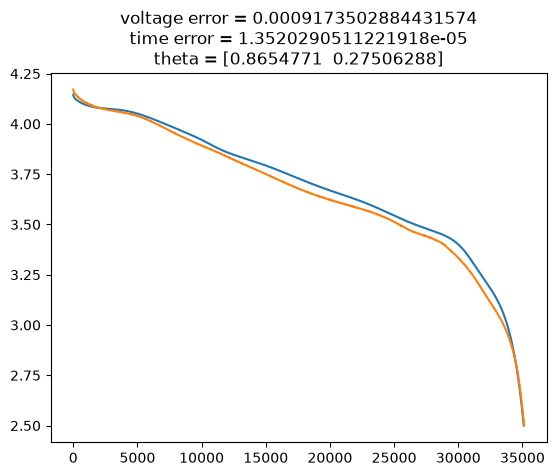

In [9]:
from scipy.optimize import least_squares
from IPython.display import clear_output

data = np.loadtxt("0.data")

dfn = DFN()

paramsDFN["I"] = lambda t: -np.mean(data[:,2]) * 1e-3 / 0.1027
paramsDFN["C_s_0_anode"] = "[input]"
paramsDFN["C_s_0_cathode"] = "[input]"

dfn.init(paramsDFN, 30, 30)
weights = np.where(data[:,0] < 1000, 6, 1)
weights = weights / np.sqrt(np.sum(weights ** 2))
t_weight = 4.0

def calc_loss(theta):
    solDFN = dfn.run({"C_s_0_anode" : theta[0] * 33133, "C_s_0_cathode" : theta[1] * 63104}, np.linspace(0, 40000, 40001))
    
    time_error = (np.abs(solDFN.t[-1] - data[-1,0]) / data[-1,0]) * t_weight
        
    v_dfn = np.interp(data[:, 0], solDFN.t, solDFN["voltage"].entries)
    voltage_error = weights * (data[:,1] - v_dfn)
    
    clear_output()
    plt.plot(solDFN.t, solDFN["voltage"].entries)
    plt.plot(data[:, 0], data[:, 1])
    plt.title(
        f"voltage error = {np.sum(voltage_error ** 2)}\n"
        f"time error = {time_error ** 2}\n"
        f"theta = {theta}"
    )
    plt.show()
    
    return np.append(voltage_error, time_error)
    

fit = least_squares(
    calc_loss,
    (0.9014, 0.27),
    diff_step=1e-2,
    bounds = (np.array([0.7, 0.1]), np.array([1.0, 0.5]))
)

theta = fit.x

### Разряд C/2

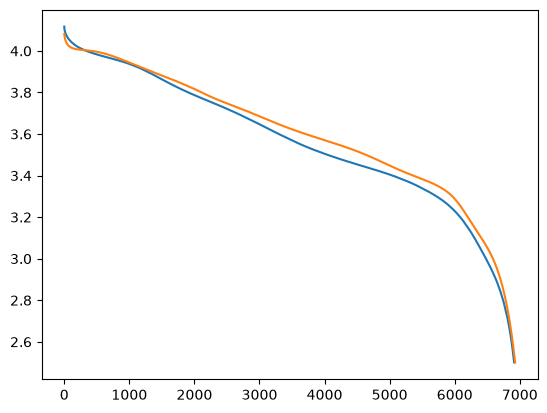

In [12]:
data = np.loadtxt("1.data")

dfn = DFN()

paramsDFN["I"] = lambda t: -np.mean(data[:,2]) * 1e-3 / 0.1027
paramsDFN["C_s_0_anode"] = theta[0] * 33133
paramsDFN["C_s_0_cathode"] = theta[1] * 63104

dfn.init(paramsDFN, 30, 30)

plt.plot(data[:,0], data[:,1])

solDFN = dfn.run({}, np.linspace(0, 8000, 8001))

plt.plot(solDFN.t, solDFN["voltage"].entries)

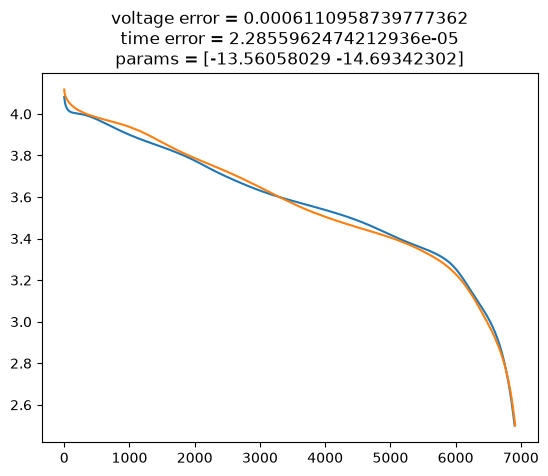

In [16]:
data = np.loadtxt("1.data")

dfn = DFN()

paramsDFN["I"] = lambda t: -np.mean(data[:,2]) * 1e-3 / 0.1027
paramsDFN["C_s_0_anode"] = theta[0] * 33133
paramsDFN["C_s_0_cathode"] = theta[1] * 63104
paramsDFN["D_s_anode"] = "[input]"
paramsDFN["D_s_cathode"] = "[input]"

dfn.init(paramsDFN, 30, 30)
weights = np.where(data[:,0] < 1000, 6, 1)
weights = weights / np.sqrt(np.sum(weights ** 2))
t_weight = 4.0

def calc_loss(Ds):
    solDFN = dfn.run({"D_s_anode" : 10 ** Ds[0], "D_s_cathode" : 10 ** Ds[1]}, np.linspace(0, 40000, 40001))
    
    time_error = (np.abs(solDFN.t[-1] - data[-1,0]) / data[-1,0]) * t_weight
        
    v_dfn = np.interp(data[:, 0], solDFN.t, solDFN["voltage"].entries)
    voltage_error = weights * (data[:,1] - v_dfn)
    
    clear_output()
    plt.plot(solDFN.t, solDFN["voltage"].entries)
    plt.plot(data[:, 0], data[:, 1])
    plt.title(
        f"voltage error = {np.sum(voltage_error ** 2)}\n"
        f"time error = {time_error ** 2}\n"
        f"params = {Ds}"
    )
    plt.show()
    
    return np.append(voltage_error, time_error)
    

fit = least_squares(
    calc_loss,
    (-14, -15),
    diff_step=1e-2,
    bounds=(np.array([-20, -20]), np.array([-3, -3]))
)

Ds = fit.x

### Все испытания

{}

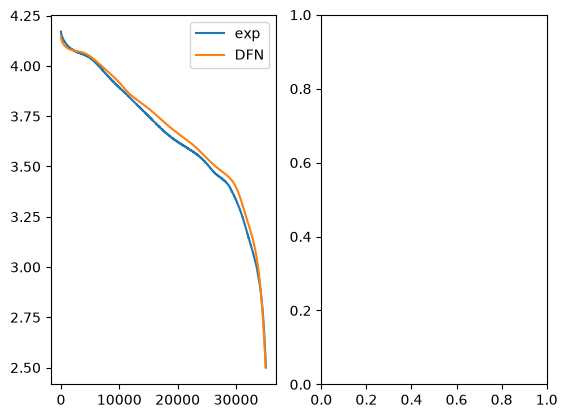

In [ ]:
# Geometry
paramsDFN["L_sep"] = "[input]"
paramsDFN["L_anode"] = "[input]"
paramsDFN["L_cathode"] = "[input]"

# Butler-Folmer anode, negative (C)
paramsDFN["Fk_anode"] = "[input]"

# Butler-Folmer cathode, positive (NMC)
paramsDFN["Fk_cathode"] = "[input]"

# Electrolyte
paramsDFN["t_plus"] = "[input]"
paramsDFN["eps_sep"] = "[input]"
paramsDFN["tau_sep"] = "[input]"
paramsDFN["tau_anode"] = "[input]"
paramsDFN["tau_cathode"] = "[input]"

# Solid anode
paramsDFN["eps_s_anode"] = "[input]"
paramsDFN["kappa_s_anode"] = "[input]"
paramsDFN["D_s_anode"] = "[input]"

# Solid cathode
paramsDFN["eps_s_cathode"] = "[input]"
paramsDFN["kappa_s_cathode"] = "[input]"
paramsDFN["D_s_cathode"] = "[input]"

# Initial
paramsDFN["C_e_0"] = "[input]"

data0 = np.loadtxt("0.data")
paramsDFN["I"] = lambda t: -np.mean(data0[:,2]) * 1e-3 / 0.1027
dfn0 = DFN()
dfn.init(paramsDFN, 30, 30)
sol0 = dfn.run({}, data0[:,0], sens=True)

fig, ax = plt.subplots(1, 2)
ax[0].plot(data0[:,0], data0[:,1], label="exp")
ax[0].plot(sol0.t, sol0["voltage"].entries, label="DFN")
ax[0].legend()

sol0.sensitivities